# 广播与 ufunc ― 数组的逐元素计算

## 本章要学什么

ufunc 是 universal function 的缩写，指的是对数组的每个元素逐个计算的函数。NumPy 内置的 ufunc 大多用 C 语言写成，因此比 Python 的循环快得多。这一章先看 ufunc 的基本用法，再确认形状不同的数组之间是怎样做计算的，也就是广播。

- ufunc 的基本用法以及 `out` 参数的作用
- 四则运算、比较运算、逻辑运算各自对应的 ufunc
- 广播的四条规则
- 用 `ogrid` 与 `mgrid` 生成格子的方法
- `reduce()`、`accumulate()`、`outer()` 这些 ufunc 的方法

先来看 ufunc 是怎么工作的：用 `linspace()` 生成一个从 $0$ 到 $2\pi$ 等分的数组，再把它交给 `np.sin()`。

In [1]:
import helper.matplotlib
import helper.magics
import numpy as np

x = np.linspace(0, 2 * np.pi, 10)
y = np.sin(x)
y

array([ 0.00000000e+00,  6.42787610e-01,  9.84807753e-01,  8.66025404e-01,
        3.42020143e-01, -3.42020143e-01, -8.66025404e-01, -9.84807753e-01,
       -6.42787610e-01, -2.44929360e-16])

`np.sin()` 是一个 ufunc，所以它对数组 `x` 的每个元素分别求正弦值，并把结果放进一个新的数组返回，计算结束之后 `x` 里的值并没有改变。

如果希望把结果写进已有的数组而不是新建一个，就要用 `out` 参数，下面的代码把计算结果直接写回 `x` 自身。

In [2]:
t = np.sin(x, out=x)   # 把结果写进 x
t is x      # True：用 out=x 写进了 x 自身

True

返回值就是计算结果，也就是 `x` 本身。`np.sin()` 也可以用在单个数值上，但只算一个数时它比标准库 `math` 里的 `sin()` 慢不少，因为为了同时接受数组和单个数值，`np.sin()` 的 C 语言实现要复杂得多。

返回值的类型也不一样：`math.sin()` 返回 Python 的 `float`，而 `np.sin()` 返回 `float64`。

In [3]:
import math

%C type(math.sin(0.5)); type(np.sin(0.5))

type(math.sin(0.5))  type(np.sin(0.5))
-------------------  -----------------
float                numpy.float64    


## 四则运算

NumPy 提供了很多 ufunc，这里以计算两个数组之和的 `add()` 为例。

In [4]:
a = np.arange(0, 4)
b = np.arange(1, 5)
np.add(a, b)                # 逐元素求和

array([1, 3, 5, 7])

`add()` 把两个数组中同一位置上的元素相加，返回一个新的数组；如果不指定 `out` 参数就会新建一个数组，指定了则把结果写入那个数组。

In [5]:
np.add(a, b, out=a)   # 把结果写进 a
a

array([1, 3, 5, 7])

NumPy 的数组也支持运算符，所以写 `a + b` 与 `np.add(a, b)` 是同一个计算，而 `np.add(a, b, out=a)` 可以写成 `a += b`。下表列出数组的运算符与对应的 ufunc。

| 表达式 | 对应的 ufunc 函数 |
|-------------|:-------------------|
|`y = x1 + x2`  |  `add(x1, x2 [, y])` |
|`y = x1 - x2`  |  `subtract(x1, x2 [, y])` |
|`y = x1 * x2`|`multiply(x1, x2 [, y])`|
|`y = x1 / x2`|    `divide(x1, x2 [, y])`|
|`y = x1 // x2`|   `floor_divide(x1, x2 [, y])`|
|`y = -x`      |   `negative(x [,y])`|
|`y = x1**x2`  |   `power(x1, x2 [, y])`|
|`y = x1 % x2` |   `remainder(x1, x2 [, y])`, `mod(x1, x2, [, y])`|

用运算符可以把表达式写得很短，但表达式一长、数组一大，中间结果就会占用好几个数组，执行速度随之下降。例如用三个数组 `a`、`b`、`c` 计算 `x = a * b + c`，实际相当于下面这样。

```python
t = a * b
x = t + c
del t
```

这里先生成一个存放乘法结果的临时数组 `t`，然后再生成结果数组 `x`；想把内存分配减少一次，就拆成下面两行来写。

```python
x = a * b
x += c
```

## 比较运算和逻辑运算

用 `==`、`>` 这类比较运算符比较两个数组时，得到的是逐元素比较结果的布尔数组。

In [6]:
np.array([1, 2, 3]) < np.array([3, 2, 1])   # 逐元素比较

array([ True, False, False])

比较运算符同样有对应的 ufunc。

| 表达式 | 对应的 ufunc 函数 |
|-------------|:-------------------|
|`y = x1 == x2`|   `equal(x1, x2 [, y]) `|
|`y = x1 != x2`|   `not_equal(x1, x2 [, y])`|
|`y = x1 < x2 `|   `less(x1, x2, [, y]) `|
|`y = x1 <= x2`|   `less_equal(x1, x2, [, y])`|
|`y = x1 > x2 `|   `greater(x1, x2, [, y])`|
|`y = x1 >= x2`|   `greater_equal(x1, x2, [, y])`|

Python 的逻辑运算用 `and`、`or`、`not`，但这些关键字无法被重载，所以数组的逻辑运算要改用对应的 ufunc。这类函数名都以 `logical_` 开头，`logical_and`、`logical_not`、`logical_or`、`logical_xor` 分别对应逻辑与、逻辑非、逻辑或和异或，下面的例子用的是 `logical_or()`。

In [7]:
a = np.arange(5)
b = np.arange(4, -1, -1)
print(a == b)
print(a > b)
print(np.logical_or(a == b, a > b))   # 与 a >= b 相同

[False False  True False False]
[False False False  True  True]
[False False  True  True  True]


对两个布尔数组使用 `and`、`or`、`not` 会抛出 `ValueError`，因为布尔数组里 `True` 和 `False` 混在一起，NumPy 无法决定该返回哪一个。

In [8]:
try:
    a == b and a > b
except Exception as ex:
    print(ex)

The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()


错误信息会提示改用数组的 `any()` 或 `all()`，这两个方法与 Python 内置函数的作用相近：`any()` 在至少有一个 `True` 时返回 `True`，`all()` 则只在所有元素都为 `True` 时返回 `True`。

In [9]:
%C np.any(a == b); np.any(a == b) and np.any(a > b)

np.any(a == b)  np.any(a == b) and np.any(a > b)
--------------  --------------------------------
np.True_        np.True_                        


以 `bitwise_` 开头的函数做的是位运算，包括 `bitwise_and`、`bitwise_not`、`bitwise_or`、`bitwise_xor` 等，用 `&`、`~`、`|`、`^` 这些运算符也能得到同样的结果。

对布尔数组来说，位运算与逻辑运算的结果相同，不过位运算符的优先级比比较运算符高，所以要让比较先算，就得加上圆括号。

In [10]:
(a == b) | (a > b)   # 不加圆括号会被解释成 a == (b | a) > b

array([False, False,  True,  True,  True])

整数数组的位运算与 C 语言里完全一样，需要注意元素类型的符号。`np.arange()` 生成的数组元素类型在 NumPy 2 里是有符号 64 位整数(int64)，把一个正数的各位取反就会得到负数：整数 0 取反之后是 `0xFFFFFFFFFFFFFFFF`，在有符号 64 位整数里这个值就是 -1。

In [11]:
%C ~np.arange(5); np.arange(5).dtype

   ~np.arange(5)      np.arange(5).dtype
--------------------  ------------------
[-1, -2, -3, -4, -5]  dtype('int64')    


如果用 8 位无符号整数做同样的运算，0 取反的结果是 `0xFF`，因为是无符号数，所以值是 255。

In [12]:
~np.arange(5, dtype=np.uint8)

array([255, 254, 253, 252, 251], dtype=uint8)

## 广播

ufunc 对两个数组同一位置的元素做计算，所以两个数组的形状必须相同；形状不同时，NumPy 会按下面的广播(broadcasting)规则处理。

① 把所有输入数组对齐到维数最多的那个数组，`shape` 属性里缺少的部分在前面补 1。

② 输出数组的 `shape` 取各输入数组 `shape` 在每一轴上的最大值。

③ 如果输入数组某一轴的长度为 1，或者与输出数组在该轴上的长度相同，这个数组就能参与计算；两者都不满足就会报错。

④ 如果输入数组某一轴的长度为 1，那么在这一轴的计算中重复使用该轴的第一个值。

这四条规则不太好懂，还是用具体的例子确认一下。

首先创建一个形状为 `(6, 1)` 的二维数组 `a`。

In [13]:
a = np.arange(0, 60, 10).reshape(-1, 1)
%C a; a.shape

  a     a.shape
------  -------
[[ 0],  (6, 1) 
 [10],         
 [20],         
 [30],         
 [40],         
 [50]]         


接着创建一个形状为 `(5,)` 的一维数组 `b`。

In [14]:
b = np.arange(0, 5)
%C b; b.shape

       b         b.shape
---------------  -------
[0, 1, 2, 3, 4]  (5,)   


计算 `a` 与 `b` 之和，就得到把两个数组所有元素两两相加的、形状为 `(6, 5)` 的加法表。

In [15]:
c = a + b
%C c; c.shape

          c             c.shape
----------------------  -------
[[ 0,  1,  2,  3,  4],  (6, 5) 
 [10, 11, 12, 13, 14],         
 [20, 21, 22, 23, 24],         
 [30, 31, 32, 33, 34],         
 [40, 41, 42, 43, 44],         
 [50, 51, 52, 53, 54]]         


`a` 与 `b` 的维数不同，所以要按规则①把 `b` 的 `shape` 对齐到 `a`，也就是在 `b` 的 `shape` 前面补 1，变成 `(1, 5)`。NumPy 2.5 已经不再推荐给 `shape` 属性赋值，因此这里改用 `reshape()`。

In [16]:
b = b.reshape(1, 5)
%C b; b.shape

        b          b.shape
-----------------  -------
[[0, 1, 2, 3, 4]]  (1, 5) 


到此为止两个输入的 `shape` 是 `(6, 1)` 和 `(1, 5)`。按规则②，输出各轴的长度取输入对应轴的最大值，于是结果是 `(6, 5)`。

`b` 第 0 轴的长度是 1，而 `a` 第 0 轴的长度是 6，所以要在第 0 轴上相加，就得把 `b` 的第 0 轴扩展到 6。

In [17]:
b = b.repeat(6, axis=0)
%C b; b.shape

        b          b.shape
-----------------  -------
[[0, 1, 2, 3, 4],  (6, 5) 
 [0, 1, 2, 3, 4],         
 [0, 1, 2, 3, 4],         
 [0, 1, 2, 3, 4],         
 [0, 1, 2, 3, 4],         
 [0, 1, 2, 3, 4]]         


`repeat()` 会沿 `axis` 指定的轴重复元素的值。同样地，`a` 第 1 轴的长度是 1，`b` 第 1 轴的长度是 5，所以再把 `a` 的第 1 轴扩展到 5。

In [18]:
a = a.repeat(5, axis=1)
%C a; a.shape

          a             a.shape
----------------------  -------
[[ 0,  0,  0,  0,  0],  (6, 5) 
 [10, 10, 10, 10, 10],         
 [20, 20, 20, 20, 20],         
 [30, 30, 30, 30, 30],         
 [40, 40, 40, 40, 40],         
 [50, 50, 50, 50, 50]]         


经过这样的处理，`a` 与 `b` 就能把同一位置的元素相加了。不过实际执行 `a + b` 时，NumPy 并不会真的用 `repeat()` 把长度为 1 的轴展开，因为那样会白白浪费内存。

NumPy 提供了 `broadcast_to()` 和 `broadcast_arrays()`，可以把数组按广播之后的形式来使用：前者把数组扩展到指定的形状。后者返回多个数组广播之后的结果，两者都与原数组共享数据区。

In [19]:
a = np.arange(0, 60, 10).reshape(-1, 1)
b = np.arange(0, 5)
a2, b2 = np.broadcast_arrays(a, b)   # 广播之后的结果
b3 = np.broadcast_to(b, (2, 3, 5))   # 把形状扩展到 (2, 3, 5)
%C a2.shape; b2.shape; b3.shape

a2.shape  b2.shape   b3.shape
--------  --------  ---------
(6, 5)    (6, 5)    (2, 3, 5)


广播用得很多，所以 NumPy 还准备了 `ogrid` 对象，可以直接生成用于广播的数组。

In [20]:
x, y = np.ogrid[:5, :5]
%C x; y

  x            y        
-----  -----------------
[[0],  [[0, 1, 2, 3, 4]]
 [1],                   
 [2],                   
 [3],                   
 [4]]                   


`mgrid` 对象的用法与之相似，区别是它直接返回广播之后的数组。

In [21]:
x, y = np.mgrid[:5, :5]
%C x; y

        x                  y        
-----------------  -----------------
[[0, 0, 0, 0, 0],  [[0, 1, 2, 3, 4],
 [1, 1, 1, 1, 1],   [0, 1, 2, 3, 4],
 [2, 2, 2, 2, 2],   [0, 1, 2, 3, 4],
 [3, 3, 3, 3, 3],   [0, 1, 2, 3, 4],
 [4, 4, 4, 4, 4]]   [0, 1, 2, 3, 4]]


`ogrid` 的用法像多维数组那样，把切片的元组当作下标，返回一组可以用于广播的数组。切片有两种写法。

* `起始值:结束值:步长`：类似 `np.arange(起始值, 结束值, 步长)`
* `起始值:结束值:长度j`：第 3 个参数写成虚数时表示返回数组的长度，类似 `np.linspace(起始值, 结束值, 长度)`

In [22]:
x, y = np.ogrid[:1:4j, :1:3j]
%C x; y

      x                 y        
--------------  -----------------
[[0.        ],  [[0. , 0.5, 1. ]]
 [0.33333333],                   
 [0.66666667],                   
 [1.        ]]                   


有了 `ogrid`，就可以很方便地计算二元函数在等间隔格子上的值。下面的程序计算并绘制三维曲面 $f(x,y) = x e^{-x^2-y^2}$。

In [23]:
x, y = np.ogrid[-2:2:20j, -2:2:20j]
z = x * np.exp(-(x**2) - y**2)

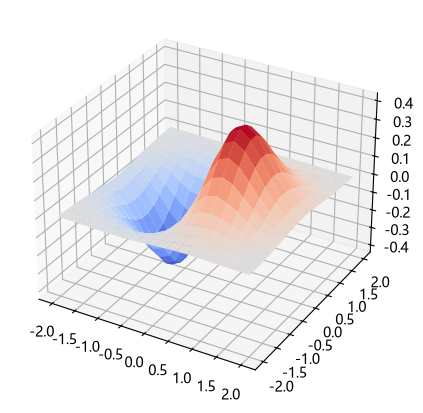

In [24]:
from matplotlib import pyplot as plt

fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(projection="3d")
surf = ax.plot_surface(x, y, z, rstride=1, cstride=1, cmap="coolwarm", linewidth=0.2)
plt.show()

要想充分利用 ufunc 的广播，常常需要先把数组的形状整理好，为此数组接受一个特殊的下标 `None`，它会在该位置新增一条长度为 1 的轴。对一维数组 `a` 来说，`a[None, :]` 与 `a.reshape(1, -1)` 相同，`a[:, None]` 与 `a.reshape(-1, 1)` 相同。

In [25]:
a = np.arange(4)
%C a[None, :]; a[:, None]

  a[None, :]    a[:, None]
--------------  ----------
[[0, 1, 2, 3]]  [[0],     
                 [1],     
                 [2],     
                 [3]]     


下面的例子用 `None` 作下标来实现广播。

In [26]:
x = np.array([0, 1, 4, 10])
y = np.array([2, 3, 8])
x[None, :] + y[:, None]

array([[ 2,  3,  6, 12],
       [ 3,  4,  7, 13],
       [ 8,  9, 12, 18]])

用 `ix_()` 可以把两个一维数组转换成能够互相广播的二维数组。

In [27]:
gy, gx = np.ix_(y, x)
%C gx; gy; gx + gy

        gx            gy        gx + gy      
------------------  -----  ------------------
[[ 0,  1,  4, 10]]  [[2],  [[ 2,  3,  6, 12],
                     [3],   [ 3,  4,  7, 13],
                     [8]]   [ 8,  9, 12, 18]]


这个例子里，`ix_()` 把数组 `x` 和 `y` 转换成可以广播的二维数组，其中数组 `y` 对应结果的第 0 轴，数组 `x` 对应第 1 轴。`ix_()` 的参数是 N 个一维数组，它把这些数组转换成能在 N 维空间里广播的 N 维数组。

## ufunc 的方法

ufunc 对象自身也有一些方法，但它们只能用在接受两个输入、产生一个输出的 ufunc 上，在别的 ufunc 上调用会抛出 `ValueError`。

`reduce()` 的调用形式是 `<op>.reduce(array, axis=0, dtype=None)`，它沿 `axis` 指定的轴，把所有元素之间都插上 `<op>` 来做计算。

In [28]:
r1 = np.add.reduce([1, 2, 3])                       # 1 + 2 + 3
r2 = np.add.reduce([[1, 2, 3], [4, 5, 6]], axis=1)  # (1+2+3), (4+5+6)
%C r1; r2

     r1         r2   
-----------  --------
np.int64(6)  [ 6, 15]


`accumulate()` 与 `reduce()` 相似，不过它返回的数组与输入形状相同，并且把中途的每一个计算结果都保存下来。

In [29]:
a1 = np.add.accumulate([1, 2, 3])
a2 = np.add.accumulate([[1, 2, 3], [4, 5, 6]], axis=1)
%C a1; a2

    a1           a2      
---------  --------------
[1, 3, 6]  [[ 1,  3,  6],
            [ 4,  9, 15]]


`outer()` 会对两个数组所有元素的组合逐一计算，效果与下面的程序相同。

```python
a.shape += (1,)*b.ndim
<op>(a, b)
a = a.squeeze()
```

其中 `squeeze()` 的作用是去掉数组里长度为 1 的轴，下面看具体的例子。

In [30]:
np.multiply.outer([1, 2, 3, 4, 5], [2, 3, 4])   # 所有组合的乘积(乘法表)

array([[ 2,  3,  4],
       [ 4,  6,  8],
       [ 6,  9, 12],
       [ 8, 12, 16],
       [10, 15, 20]])

`outer()` 的结果就是一张乘法表。用上面的程序一行一行地做同样的计算，就能看出这张乘法表正是靠广播算出来的。

## 小结

* ufunc 是对数组元素逐个计算的函数，因为用 C 语言实现所以很快；把数组传给 `out` 参数，就能把结果写进那个数组。
* 四则运算、比较运算、逻辑运算、位运算各有对应的 ufunc，而布尔数组上不能使用 `and`、`or`、`not`。
* ufunc 也能计算形状不同的数组，这叫广播，做法是把长度为 1 的轴扩展到输出的长度。
* 用 `None` 作下标可以新增长度为 1 的轴，而 `ogrid` 与 `mgrid` 能生成格子状的数组。
* `reduce()`、`accumulate()`、`outer()` 是 ufunc 的方法，用来沿轴汇总或者对所有元素组合做计算。